# Лабораторная работа №3. Построение и оценка моделей машинного обучения
**ФИО:** Лазуткина М.В.
**Группа:** ИУ3-71Б
**Вариант:** 7

In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

VARIANT = 7
DATASETS = ["iris", "wine", "cancer", "digits", "penguins",
            "titanic", "mpg_origin", "diabetes", "mpg_reg", "diamonds"]
MODELS = {
    "iris": ["logistic", "tree", "svc"],
    "wine": ["logistic", "gnb", "forest"],
    "cancer": ["logistic", "svc", "forest"],
    "digits": ["logistic", "svc", "forest"],
    "penguins": ["tree", "forest", "logistic"],
    "titanic": ["logistic", "gbc", "forest"],
    "mpg_origin": ["tree", "svc", "forest"],
    "diabetes": ["ridge", "lasso", "forest_reg"],
    "mpg_reg": ["ridge", "svr", "gbr"],
    "diamonds": ["ridge", "forest_reg", "hist_reg"],
}
DATASET = DATASETS[(VARIANT - 1) % 10]
MODEL = MODELS[DATASET][(VARIANT - 1) // 10]
CLASSIFICATION = DATASET not in {"diabetes", "mpg_reg", "diamonds"}
print(DATASET, MODEL)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

mpg_origin tree


**Вариант 7. Набор № 7: Auto MPG, DecisionTreeClassifier**

*Части 1–2.* Классификация origin по 6 числовым характеристикам автомобиля. Модель: DecisionTreeClassifier. Сетка поиска: max_depth: 2, 4, 6, None; min_samples_leaf: 1, 3, 7.

Контроль: лучшие параметры: max_depth=None, min_samples_leaf=1; accuracy на CV 0,796 ± 0,043, на тесте 0,873; константный прогноз 0,620.

## Часть 1. Данные, pipeline и константный прогноз
**1.** Описать объект и целевую переменную, вывести размер, первые строки, пропуски и распределение классов или описательные статистики ответа. Убедиться, что среди признаков нет ответа и его производных.

In [2]:
from sklearn.datasets import (load_iris, load_wine, load_breast_cancer,
                              load_digits, load_diabetes)

SB = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/"
categorical = []

if DATASET in {"iris", "wine", "cancer", "digits", "diabetes"}:
    loaders = {"iris": load_iris, "wine": load_wine, "cancer": load_breast_cancer,
               "digits": load_digits, "diabetes": load_diabetes}
    d = loaders[DATASET](scaled=False) if DATASET == "diabetes" else loaders[DATASET]()
    X = pd.DataFrame(d.data, columns=d.feature_names)
    y = pd.Series(d.target, name="target")
elif DATASET == "penguins":
    raw = pd.read_csv(SB + "penguins.csv")
    numeric = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
    categorical = ["island", "sex"]
    raw = raw.dropna(subset=numeric + categorical + ["species"]).reset_index(drop=True)
    X, y = raw[numeric + categorical], raw["species"]
elif DATASET == "titanic":
    raw = pd.read_csv(SB + "titanic.csv")
    numeric = ["pclass", "age", "sibsp", "parch", "fare"]
    categorical = ["sex", "embarked"]
    X, y = raw[numeric + categorical], raw["survived"]
elif DATASET in {"mpg_origin", "mpg_reg"}:
    raw = pd.read_csv(SB + "mpg.csv").dropna().reset_index(drop=True)
    numeric = ["cylinders", "displacement", "horsepower", "weight",
               "acceleration", "model_year"]
    X = raw[numeric]
    y = raw["origin" if DATASET == "mpg_origin" else "mpg"]
elif DATASET == "diamonds":
    raw = pd.read_csv(SB + "diamonds.csv").sample(3000, random_state=42)
    numeric = ["carat", "depth", "table", "x", "y", "z"]
    categorical = ["cut", "color", "clarity"]
    X, y = raw[numeric + categorical], raw["price"]

numeric = X.select_dtypes(include=np.number).columns.tolist()
print(X.shape, y.shape)
display(X.head())
display(X.isna().sum())

(392, 6) (392,)


,cylinders,displacement,horsepower,weight,acceleration,model_year
0,8,307.0,130.0,3504,12.0,70
1,8,350.0,165.0,3693,11.5,70
2,8,318.0,150.0,3436,11.0,70
3,8,304.0,150.0,3433,12.0,70
4,8,302.0,140.0,3449,10.5,70


,0
cylinders,0
displacement,0
horsepower,0
weight,0
acceleration,0
model_year,0


In [3]:
print("Все столбцы исходной таблицы:", list(raw.columns))
print("Признаки модели:", list(X.columns))
display(pd.DataFrame({"автомобилей": y.value_counts(), "доля": y.value_counts(normalize=True).round(3)}))
display(X.describe().round(1))

Все столбцы исходной таблицы: ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin', 'name']
Признаки модели: ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year']


,автомобилей,доля
origin,,
usa,245,0.625
japan,79,0.202
europe,68,0.173


,cylinders,displacement,horsepower,weight,acceleration,model_year
count,392.0,392.0,392.0,392.0,392.0,392.0
mean,5.5,194.4,104.5,2977.6,15.5,76.0
std,1.7,104.6,38.5,849.4,2.8,3.7
min,3.0,68.0,46.0,1613.0,8.0,70.0
25%,4.0,105.0,75.0,2225.2,13.8,73.0
50%,4.0,151.0,93.5,2803.5,15.5,76.0
75%,8.0,275.8,126.0,3614.8,17.0,79.0
max,8.0,455.0,230.0,5140.0,24.8,82.0


**Описание.** Объект — одна модель автомобиля 1970–1982 гг. (392 строки после удаления 6 строк с пропуском `horsepower`). Целевая переменная `origin` — регион производителя: `usa`, `japan`, `europe`. Признаки: `cylinders` — число цилиндров, `displacement` — рабочий объём двигателя (куб. дюймы), `horsepower` — мощность (л. с.), `weight` — масса (фунты), `acceleration` — время разгона до 60 миль/ч (с), `model_year` — год модели (70–82). Столбцы `mpg` (расход) и `name` (название модели) в признаки не входят; `name` фактически содержит марку и раскрывал бы регион. Ответа и его производных среди признаков нет. Классы несбалансированы: 62,5 % американских автомобилей.

**2.** Разделить данные на обучающую и тестовую части в отношении 80:20.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
    stratify=y if CLASSIFICATION else None)
cv = (StratifiedKFold(5, shuffle=True, random_state=42) if CLASSIFICATION
      else KFold(5, shuffle=True, random_state=42))
print("Обучающая:", X_train.shape, "| тестовая:", X_test.shape)
display(pd.DataFrame({"обучающая": y_train.value_counts(), "тестовая": y_test.value_counts()}))

Обучающая: (313, 6) | тестовая: (79, 6)


,обучающая,тестовая
origin,,
usa,196,49
japan,63,16
europe,54,14


**3.** Собрать pipeline по п. 1.2. Для logistic, gnb, svc, svr, ridge, lasso числовые признаки стандартизировать; для деревьев и ансамблей — нет. Модель и сетку взять из карточки.

In [5]:
scale = MODEL in {"logistic", "svc", "svr", "ridge", "lasso", "gnb"}
num_steps = [("imputer", SimpleImputer(strategy="median"))]
if scale:
    num_steps.append(("scaler", StandardScaler()))
transformers = [("num", Pipeline(num_steps), numeric)]
if categorical:
    transformers.append(("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), categorical))
preprocess = ColumnTransformer(transformers, verbose_feature_names_out=False)

model = DecisionTreeClassifier(random_state=42)
param_grid = {"model__max_depth": [2, 4, 6, None],
              "model__min_samples_leaf": [1, 3, 7]}
pipe = Pipeline([("preprocess", preprocess), ("model", model)])
pipe

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['cylinders', 'displacement',
                                                   'horsepower', 'weight',
                                                   'acceleration',
                                                   'model_year'])],
                                   verbose_feature_names_out=False)),
                ('model', DecisionTreeClassifier(random_state=42))])

Pipeline нужен, чтобы не было утечки данных, перекрёстная проверка.Масштабирования нет, потому что дерево.


**4.** Обучить константный прогноз и вычислить его тестовую accuracy или MAE. Это справочная величина, а не кандидат при настройке.

In [18]:
from sklearn.metrics import accuracy_score, mean_absolute_error, r2_score

baseline = (DummyClassifier(strategy="most_frequent") if CLASSIFICATION
            else DummyRegressor(strategy="mean"))
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
baseline_score = (accuracy_score(y_test, baseline_pred) if CLASSIFICATION
                  else mean_absolute_error(y_test, baseline_pred))
print("Константный прогноз - ориентир, модель должна работать лучше: всегда", baseline_pred[0])
print("Константный прогноз:", round(baseline_score, 3))

Константный прогноз - ориентир, модель должна работать лучше: всегда usa
Константный прогноз: 0.62


## Часть 2. Настройка и итоговая оценка
**1.** Выполнить GridSearchCV только на X_train, y_train с полной сеткой карточки и пятикратной CV. Для классификации использовать StratifiedKFold(5, shuffle=True, random_state=42), для регрессии — KFold с теми же параметрами.

**2.** Вывести лучшие параметры, среднюю метрику CV и её стандартное отклонение. Построить график: тепловую карту для двух параметров или кривую для одного.

**3.** Обучить лучший pipeline (это уже делает refit) и один раз вычислить тестовую accuracy либо MAE и R2. Сравнить с константным прогнозом.

**4.** Сверить параметры и метрики с контрольными значениями карточки.

In [7]:
search = GridSearchCV(
    pipe, param_grid,
    scoring="accuracy" if CLASSIFICATION else "neg_mean_absolute_error",
    cv=cv, n_jobs=-1)
search.fit(X_train, y_train)
cv_mean = search.best_score_
cv_std = search.cv_results_["std_test_score"][search.best_index_]
print("Лучшие параметры:", search.best_params_)
print(f"Лучшая CV-оценка: {cv_mean:.3f} ± {cv_std:.3f}")

res = pd.DataFrame(search.cv_results_)[["param_model__max_depth", "param_model__min_samples_leaf",
                                        "mean_test_score", "std_test_score", "rank_test_score"]]
res.columns = ["max_depth", "min_samples_leaf", "accuracy CV, среднее", "accuracy CV, ст. откл.", "место"]
res["max_depth"] = [str(v) if v is not None and not pd.isna(v) else "None" for v in search.cv_results_["param_model__max_depth"]]
display(res.sort_values("место").round(3).reset_index(drop=True))

Лучшие параметры: {'model__max_depth': None, 'model__min_samples_leaf': 1}
Лучшая CV-оценка: 0.796 ± 0.043


,max_depth,min_samples_leaf,"accuracy CV, среднее","accuracy CV, ст. откл.",место
0,None,1,0.796,0.043,1
1,6,1,0.792,0.030,2
2,None,3,0.757,0.065,3
3,4,3,0.757,0.078,4
4,6,3,0.757,0.052,4
5,4,1,0.748,0.059,6
6,None,7,0.745,0.035,7
7,6,7,0.745,0.035,7
8,4,7,0.735,0.043,9
9,2,3,0.690,0.047,10


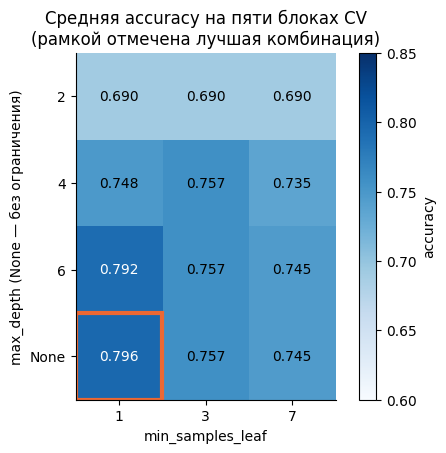

In [8]:
depths = ["2", "4", "6", "None"]
leaves = [1, 3, 7]
heat = res.pivot(index="max_depth", columns="min_samples_leaf", values="accuracy CV, среднее").loc[depths, leaves]

fig, ax = plt.subplots(figsize=(6, 4.5))
im = ax.imshow(heat.values, cmap="Blues", vmin=0.6, vmax=0.85)
for i in range(len(depths)):
    for j in range(len(leaves)):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", color="white" if v > 0.76 else "black")
bi = depths.index(str(search.best_params_["model__max_depth"]))
bj = leaves.index(search.best_params_["model__min_samples_leaf"])
ax.add_patch(plt.Rectangle((bj - 0.5, bi - 0.5), 1, 1, fill=False, ec="#eb6834", lw=3))
ax.set(xticks=range(len(leaves)), xticklabels=leaves, yticks=range(len(depths)), yticklabels=depths,
       xlabel="min_samples_leaf", ylabel="max_depth (None — без ограничения)",
       title="Средняя accuracy на пяти блоках CV\n(рамкой отмечена лучшая комбинация)")
fig.colorbar(im, ax=ax, label="accuracy")
plt.show()

In [9]:
best = search.best_estimator_
pred = best.predict(X_test)
test_acc = accuracy_score(y_test, pred)
print("Test accuracy:", round(test_acc, 3))
print("Константный прогноз:", round(baseline_score, 3))
print(f"Улучшение над константным прогнозом: {(test_acc - baseline_score) * 100:.1f} п. п.")

Test accuracy: 0.873
Константный прогноз: 0.62
Улучшение над константным прогнозом: 25.3 п. п.


In [10]:
check = pd.DataFrame({
    "получено": [str(search.best_params_["model__max_depth"]), str(search.best_params_["model__min_samples_leaf"]),
                 f"{cv_mean:.3f} ± {cv_std:.3f}", f"{test_acc:.3f}", f"{baseline_score:.3f}"],
    "контроль": ["None", "1", "0.796 ± 0.043", "0.873", "0.620"],
}, index=["max_depth", "min_samples_leaf", "accuracy на CV", "accuracy на тесте", "константный прогноз"])
check["совпадает"] = np.where(check["получено"] == check["контроль"], "да", "нет")
display(check)

,получено,контроль,совпадает
max_depth,None,None,да
min_samples_leaf,1,1,да
accuracy на CV,0.796 ± 0.043,0.796 ± 0.043,да
accuracy на тесте,0.873,0.873,да
константный прогноз,0.620,0.620,да


**Сравнение с контрольными значениями и выводы:**

1. Все значения совпали с контролем: лучшие параметры `max_depth=None`, `min_samples_leaf=1`, accuracy на CV 0,796 ± 0,043, на тесте 0,873, константный прогноз 0,620.
2. Дерево на 25 п. п. лучше константного прогноза «всегда usa» (0,873 против 0,620), то есть по техническим характеристикам регион определяется заметно лучше случайного.
3. Победило самое сложное дерево (без ограничения глубины, лист из одного объекта), но преимущество над соседними клетками сетки невелико: `max_depth=6, min_samples_leaf=1` даёт 0,792 — всего на 0,004 меньше, а разброс по блокам ± 0,043 в десять раз больше этой разницы. Выбор лучшей комбинации не очень устойчив.
4. Тестовая accuracy (0,873) выше CV-оценки (0,796). Тест — это всего 79 автомобилей, и одна ошибка меняет accuracy на 1,3 п. п., поэтому более надёжной оценкой качества следует считать CV.

## Часть 3. Индивидуальный эксперимент
**2.** Выведите глубину, число листьев и важности признаков. Постройте матрицу ошибок: какие регионы путаются? Объясните разбиения дерева по важнейшему признаку.

Контроль: глубина 10, листьев 47; главный признак: displacement (0,490); путаница europe → japan (3).

Глубина дерева: 10
Число листьев: 47


,важность
displacement,0.490
weight,0.153
horsepower,0.139
acceleration,0.128
model_year,0.052
cylinders,0.038


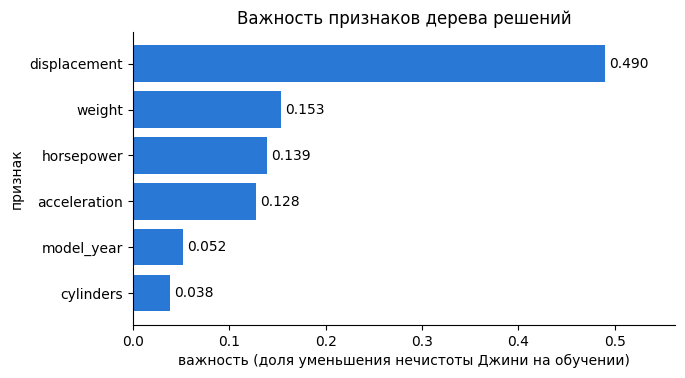

In [11]:
tree = best.named_steps["model"]
feature_names = best.named_steps["preprocess"].get_feature_names_out()
print("Глубина дерева:", tree.get_depth())
print("Число листьев:", tree.get_n_leaves())

imp = pd.Series(tree.feature_importances_, index=feature_names).sort_values()
display(imp.sort_values(ascending=False).round(3).to_frame("важность"))

fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.barh(imp.index, imp.values, color="#2a78d6")
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set(xlabel="важность (доля уменьшения нечистоты Джини на обучении)", ylabel="признак",
       title="Важность признаков дерева решений", xlim=(0, imp.max() * 1.15))
plt.show()

Важность считается при обучении: для каждого вопроса дерева берётся, насколько он уменьшил нечистоту Джини, с учётом числа машин в узле; вклады суммируются по признакам и нормируются до суммы 1

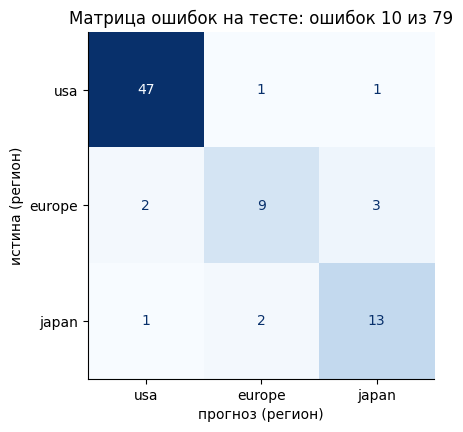

,истина,прогноз,ошибок
0,europe,japan,3
1,europe,usa,2
2,japan,europe,2
3,usa,europe,1
4,usa,japan,1
5,japan,usa,1


Доля верно распознанных по регионам (recall): {'usa': 0.959, 'europe': 0.643, 'japan': 0.812}


In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

labels = ["usa", "europe", "japan"]
cm = confusion_matrix(y_test, pred, labels=labels)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set(xlabel="прогноз (регион)", ylabel="истина (регион)",
       title=f"Матрица ошибок на тесте: ошибок {cm.sum() - np.trace(cm)} из {cm.sum()}")
plt.show()

errors = pd.crosstab(y_test, pred, rownames=["истина"], colnames=["прогноз"])
pairs = [(t, p, cm[i, j]) for i, t in enumerate(labels) for j, p in enumerate(labels) if i != j and cm[i, j] > 0]
pairs = pd.DataFrame(pairs, columns=["истина", "прогноз", "ошибок"]).sort_values("ошибок", ascending=False)
display(pairs.reset_index(drop=True))
recall = pd.Series(np.diag(cm) / cm.sum(axis=1), index=labels)
print("Доля верно распознанных по регионам (recall):", recall.round(3).to_dict())

Поэтому одной accuracy 0,873 мало — она скрывает, что один класс распознаётся заметно хуже

In [13]:
from sklearn.tree import export_text

print(export_text(tree, feature_names=list(feature_names), max_depth=2, show_weights=True))
print("Порядок классов в weights:", list(tree.classes_))444

is_disp = tree.tree_.feature == list(feature_names).index("displacement")
print("Разбиений по displacement:", is_disp.sum(), "из", (tree.tree_.feature >= 0).sum())
print("Пороги:", np.sort(tree.tree_.threshold[is_disp]).round(1))

|--- displacement <= 134.50
|   |--- displacement <= 97.25
|   |   |--- acceleration <= 19.45
|   |   |   |--- truncated branch of depth 7
|   |   |--- acceleration >  19.45
|   |   |   |--- truncated branch of depth 4
|   |--- displacement >  97.25
|   |   |--- horsepower <= 86.50
|   |   |   |--- truncated branch of depth 7
|   |   |--- horsepower >  86.50
|   |   |   |--- truncated branch of depth 8
|--- displacement >  134.50
|   |--- displacement <= 170.50
|   |   |--- weight <= 3071.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- weight >  3071.50
|   |   |   |--- weights: [6.00, 0.00, 0.00] class: europe
|   |--- displacement >  170.50
|   |   |--- weights: [0.00, 0.00, 141.00] class: usa

Порядок классов в weights: ['europe', 'japan', 'usa']
Разбиений по displacement: 10 из 46
Пороги: [ 97.2 107.5 109.5 114.5 121.  121.5 128.  132.5 134.5 170.5]


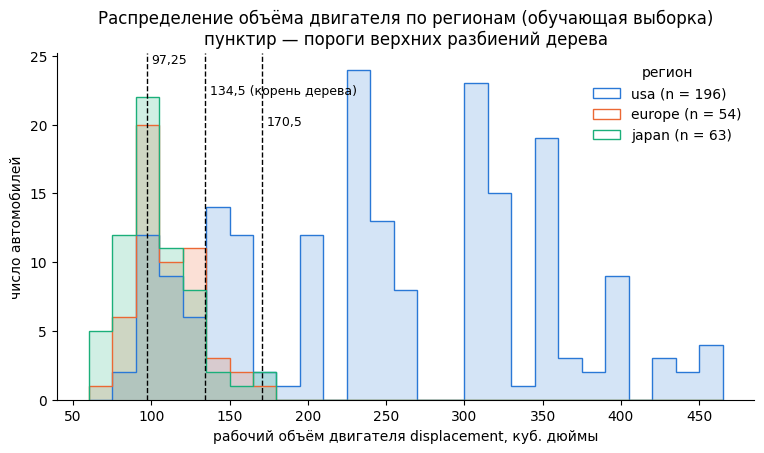

,count,min,50%,max
origin,,,,
europe,54.0,68.0,104.5,168.0
japan,63.0,70.0,97.0,168.0
usa,196.0,85.0,250.0,455.0


In [14]:
colors = {"usa": "#2a78d6", "europe": "#eb6834", "japan": "#1baf7a"}
bins = np.arange(60, 470, 15)
fig, ax = plt.subplots(figsize=(9, 4.5))
for o in labels:
    v = X_train.loc[y_train == o, "displacement"]
    ax.hist(v, bins=bins, histtype="stepfilled", alpha=0.2, color=colors[o])
    ax.hist(v, bins=bins, histtype="step", lw=2, color=colors[o], label=f"{o} (n = {len(v)})")
ymax = ax.get_ylim()[1]
for thr, txt, h in [(97.25, "97,25", 0.97), (134.5, "134,5 (корень дерева)", 0.88), (170.5, "170,5", 0.79)]:
    ax.axvline(thr, color="black", ls="--", lw=1)
    ax.text(thr + 3, ymax * h, txt, fontsize=9)
ax.set(xlabel="рабочий объём двигателя displacement, куб. дюймы", ylabel="число автомобилей",
       title="Распределение объёма двигателя по регионам (обучающая выборка)\nпунктир — пороги верхних разбиений дерева")
ax.legend(title="регион", frameon=False)
plt.show()

display(X_train.groupby(y_train)["displacement"].describe()[["count", "min", "50%", "max"]].round(1))

**Результаты эксперимента и интерпретация:**

1. *Наблюдение.* Дерево имеет глубину 10 и 47 листьев (на 313 обучающих объектов), главный признак — `displacement` (важность 0,490), далее `weight` (0,153) и `horsepower` (0,139). Все значения совпали с контролем.
2. *Наблюдение.* На тесте 10 ошибок из 79. Американские автомобили распознаются почти безошибочно (47 из 49), а европейские хуже всего: верно только 9 из 14. Самая частая путаница — europe → japan (3 случая), затем japan → europe (2) и europe → usa (2).
3. *Интерпретация разбиений.* Первое разбиение — `displacement ≤ 134,5`: у американских машин медианный объём 250 куб. дюймов, у европейских и японских ≈ 100, поэтому этот порог отделяет большие американские двигатели. Правее порога 170,5 в обучающей выборке остаются только американские машины (141 из 141, чистый лист). Левая ветвь (малые двигатели) содержит почти все европейские и японские машины, и дальше дерево пытается разделить их уже по `displacement ≤ 97,25`, `horsepower`, `acceleration` и `weight`. Всего по `displacement` сделано 10 из 46 разбиений.
4. *Интерпретация ошибок.* Европа и Япония путаются потому, что в этот период обе выпускали компактные машины с малыми двигателями, и по 6 техническим характеристикам их диапазоны почти совпадают (медианы объёма 104,5 и 97 куб. дюймов). Американские же машины выделяются размером.
5. *Ограничения.* Тест мал (14 европейских и 16 японских машин), поэтому recall по этим классам неустойчив. Важность признаков дерева считается на обучении и завышает вклад непрерывных и коррелированных признаков: `displacement`, `weight`, `horsepower` и `cylinders` сильно связаны, и выбор дерева между ними во многом случаен. Наконец, связь «объём → регион» — это наблюдаемая закономерность рынка 1970-х, а не причинная зависимость.

## Часть 4. Сохранение и применение модели
**3.** Сохраните весь обученный pipeline в model_v7.joblib, загрузите его в новой ячейке и проверьте совпадение прогнозов на тесте. Сделайте прогноз для одного объекта в исходных единицах.

In [15]:
path = f"model_v{VARIANT}.joblib"
joblib.dump(best, path)
print("Сохранено:", path)

Сохранено: model_v7.joblib


In [16]:
loaded = joblib.load(path)
loaded_pred = loaded.predict(X_test)
print("Прогнозы совпадают:",
      np.array_equal(pred, loaded_pred) if CLASSIFICATION
      else np.allclose(pred, loaded_pred))

sample = X_test.iloc[[0]]
print(sample)
print("Истина:", y_test.iloc[0], "Прогноз:", loaded.predict(sample)[0])

Прогнозы совпадают: True
     cylinders  displacement  horsepower  weight  acceleration  model_year
350          4         107.0        75.0    2210          14.4          81
Истина: japan Прогноз: europe


## Общие выводы

1. Получено дерево решений (`max_depth=None`, `min_samples_leaf=1`, глубина 10, 47 листьев), которое определяет регион производителя по 6 техническим характеристикам с accuracy 0,796 ± 0,043 на пятикратной CV и 0,873 на отложенном тесте. Это на 25 п. п. лучше константного прогноза «всегда usa» (0,620). Все числа совпали с контрольными.
2. Главный признак — рабочий объём двигателя (`displacement`, важность 0,490): одно разбиение `displacement ≤ 134,5` почти полностью отделяет американские автомобили.
3. Характерная ошибка — путаница Европы и Японии (europe → japan 3 раза, japan → europe 2 раза): у компактных машин этих регионов близкие характеристики. Европейские машины распознаются хуже всего (9 из 14).
4. Условия проверки: 392 автомобиля, стратифицированное разбиение 80:20 и 5-кратная CV с `random_state=42`; тест использован один раз. Тест мал (79 объектов), а дерево без ограничений склонно к переобучению, поэтому оценку 0,873 следует считать оптимистичной; надёжнее ориентироваться на CV ≈ 0,80.
5. Весь pipeline сохранён в `model_v7.joblib`; после загрузки прогнозы на тесте полностью совпали. Первый тестовый объект — японский автомобиль 1981 г. с объёмом 107 куб. дюймов — модель отнесла к Европе: это как раз характерная путаница двух регионов с компактными машинами.